[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L7/BA_L7_volume/BA_L7_volume.ipynb)

# BA_L7_volume: Persistence of Bitcoin trading volume, January 2022 - October 2023

*Quantlet of Lecture 7, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Log daily Bitcoin trading volume (EODHD) over the sample of the BitMood volume forecasts, its autocorrelation, weekly pattern and an AR(1) fit: the lagged-volume benchmark a sentiment model must beat.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Method

The BitMood study forecasts daily Bitcoin trading volume (January 2022 – October 2023) from sentiment and lagged volume. Any sentiment model
must beat a forecast from past volume alone. The cell measures the persistence of the log of daily volume over 1 January 2022 – 15 October 2023:
autocorrelations, the mean of each weekday, an autoregression of order 1, AR(1), and the root mean squared error (RMSE, in logs) of the sample mean,
of "same as yesterday" and of the AR(1).

653 days; autocorrelation: lag 1 0.78, lag 7 0.74, lag 30 0.39
Log volume minus its mean: Saturday -0.33, Sunday -0.28
AR(1) R^2 = 0.61; RMSE (logs): mean 0.50, same as yesterday 0.33, AR(1) 0.31


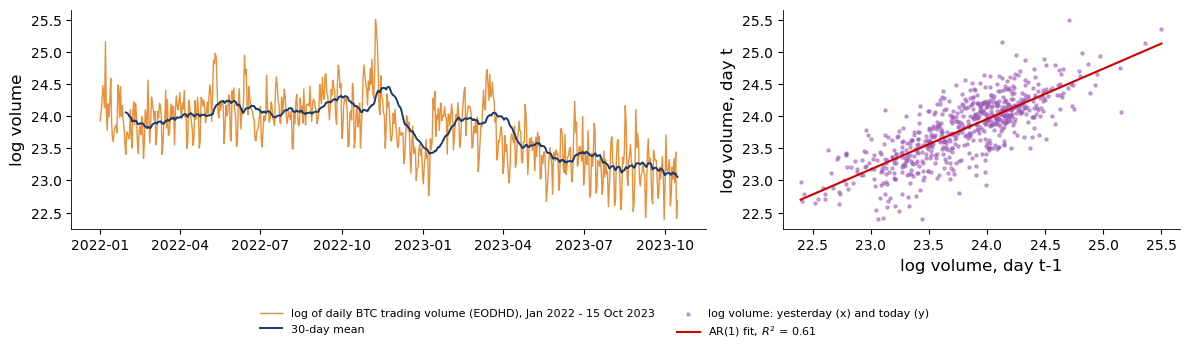

In [5]:
d = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date').loc[:END]
v = np.log(d['volume'].replace(0, np.nan)).dropna().loc['2022-01-01':'2023-10-15']
x1, y1 = v.shift(1).dropna(), v.iloc[1:]
b1, a1 = np.polyfit(x1, y1, 1)
res = y1 - (a1 + b1 * x1)
r2 = 1 - res.var() / y1.var()
print(f'{len(v)} days; autocorrelation: lag 1 {v.autocorr(1):.2f}, lag 7 {v.autocorr(7):.2f}, lag 30 {v.autocorr(30):.2f}')
dev = v.groupby(v.index.dayofweek).mean() - v.mean()
print(f'Log volume minus its mean: Saturday {dev[5]:+.2f}, Sunday {dev[6]:+.2f}')
print(f'AR(1) R^2 = {r2:.2f}; RMSE (logs): mean {np.sqrt(np.mean((y1 - y1.mean()) ** 2)):.2f}, '
      f'same as yesterday {np.sqrt(np.mean((y1 - x1) ** 2)):.2f}, AR(1) {np.sqrt(np.mean(res ** 2)):.2f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].plot(v.index, v, color=BTC, lw=1.0, label='log of daily BTC trading volume (EODHD), Jan 2022 - 15 Oct 2023')
ax[0].plot(v.index, v.rolling(30).mean(), color=BLUE, lw=1.4, label='30-day mean')
ax[0].set_ylabel('log volume')
ax[1].scatter(x1, y1, s=5, color=ETH, alpha=0.5, label='log volume: yesterday (x) and today (y)')
xx = np.linspace(x1.min(), x1.max(), 20)
ax[1].plot(xx, a1 + b1 * xx, color=RED, lw=1.5, label=f'AR(1) fit, $R^2$ = {r2:.2f}')
ax[1].set_xlabel('log volume, day t-1'); ax[1].set_ylabel('log volume, day t')
slide_fig(fig, 'ba_l7_volume', 0.16, ncol=2)

**How to read it.** Yesterday's volume already explains about 60% of today's: a sentiment model is useful only if it lowers the error of this
benchmark on the same test days.